# Coil Sensitivity and Perturbation Analysis

Interactive companion to `perturbation_analysis.tex`, ported from `visualise.py`.
It reproduces the sensitivity / perturbation study of the $4\times4$ sub-coil array:

1. Magnetic-field model (in-phase $\mathbf{u}$ / quadrature $\mathbf{v}$ decomposition).
2. Perturbation losses under additive Gaussian $\mathfrak{se}(3)$ pose noise.
3. Loss landscapes over the design parameters $(\theta,\, z_{\mathrm{focal}})$.
4. The optimal coil configuration, modelled and returned explicitly, and drawn as cylinders.
5. An interactive 3D surface, at a layer selected with a slider, whose local surface
   normal equals the local magnetic-field rotation axis
   $\mathbf{n}_{\mathrm{rot}}(\mathbf{r})$.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft2, ifft2, fftfreq
from IPython.display import display, clear_output
import ipywidgets as widgets

plt.rcParams["figure.dpi"] = 110
np.random.seed(0)  # reproducible Monte-Carlo noise draws

## 1. Parameters and geometry

A $4\times4$ grid of sub-coils sits on the $z=0$ plane with spacing $2.6\ \mathrm{cm}$.
The grid is split into four $2\times2$ clusters, each driven with a $90^\circ$ phase
offset so the superposed field traces a rotating ellipse. The cylinder dimensions
come from the hardware model in `mag.py`.

In [2]:
# ---------------------------------------------------------------------------
# Physical parameters and array geometry
# ---------------------------------------------------------------------------
spacing = 0.026  # Grid spacing (2.6 cm)
grid_coords = np.array([-1.5, -0.5, 0.5, 1.5]) * spacing  # [-3.9, -1.3, 1.3, 3.9] cm
positions = np.array([[x, y, 0.0] for x in grid_coords for y in grid_coords])

# Cluster mapping (4x4 grid split into four 2x2 clusters)
cluster_map = np.array(
    [
        (0 if i >= 2 else 1) if j >= 2 else (3 if i >= 2 else 2)
        for i in range(4)
        for j in range(4)
    ]
)
cluster_phases = np.array([0.0, np.pi / 2, np.pi, 3 * np.pi / 2])

I0 = 1.25            # Peak AC current (A)
K_dipole = 5.629e-5  # Dipole constant T*m^3/A
sigma_rot = np.radians(0.5)  # Pose rotation noise (rad)
sigma_trans = 0.0002         # Pose translation noise (m)

# Sub-coil cylinder dimensions (from mag.py)
COIL_RADIUS = 0.0105  # 1.05 cm
COIL_HEIGHT = 0.0150  # 1.50 cm

N_COILS = len(positions)
print(f"{N_COILS} sub-coils, spacing {spacing*100:.1f} cm")

16 sub-coils, spacing 2.6 cm


## 2. Coil normal generator

Three base topologies are available:

| Topology | Description |
|---|---|
| `baseline` | All coils point along $+z$. |
| `cluster_tilt` | Each $2\times2$ cluster tilts by `theta_deg` about its centre (positive = inward). |
| `focal_convergent` | Each coil aims at a common focal point `z_focal` above the array. |

The *hybrid* topology blends the latter two and is what the design sweep optimises.

In [3]:
def get_coil_normals(topology, theta_deg=0.0, z_focal=0.045):
    """Unit orientation vector n for every sub-coil under a given topology."""
    normals = []
    cluster_centers = np.zeros((4, 2))
    for c_id in range(4):
        cluster_centers[c_id] = np.mean(positions[cluster_map == c_id, :2], axis=0)

    for k, p in enumerate(positions):
        c_id = cluster_map[k]
        if topology == "baseline":
            normals.append([0.0, 0.0, 1.0])
        elif topology == "cluster_tilt":
            c_ctr = cluster_centers[c_id]
            r_dir = -c_ctr / np.linalg.norm(c_ctr)
            rad = np.radians(theta_deg)
            nx = r_dir[0] * np.sin(rad)
            ny = r_dir[1] * np.sin(rad)
            nz = np.cos(rad)
            normals.append([nx, ny, nz])
        elif topology == "focal_convergent":
            v = np.array([-p[0], -p[1], z_focal - p[2]])
            normals.append(v / np.linalg.norm(v))

    return np.array(normals)


def hybrid_normals(theta_deg, z_focal):
    """Equal-weight blend of the cluster-tilt and focal-convergent topologies."""
    n = 0.5 * (
        get_coil_normals("cluster_tilt", theta_deg=theta_deg)
        + get_coil_normals("focal_convergent", z_focal=z_focal)
    )
    return n / np.linalg.norm(n, axis=1, keepdims=True)

## 3. Magnetic-field model

Under the point-dipole approximation the field of sub-coil $(i,j)$ at $\mathbf{r}$ is
$\mathbf{b}_{i,j}(\mathbf{r}) = K_{\mathrm{dipole}}\left(\frac{3(\mathbf{r}_{i,j}\cdot\mathbf{n}_{i,j})\mathbf{r}_{i,j}}{d_{i,j}^5} - \frac{\mathbf{n}_{i,j}}{d_{i,j}^3}\right)$.
Superposing the 16 phase-shifted coils and separating the $\cos\omega t$ / $\sin\omega t$
parts gives
$$\mathbf{u} = I_0\sum \mathbf{b}_{i,j}\cos\psi_{i,j}, \qquad
  \mathbf{v} = -I_0\sum \mathbf{b}_{i,j}\sin\psi_{i,j},$$
from which we derive the rotation vector $\mathbf{w} = \mathbf{u}\times\mathbf{v}$, the
rotation axis $\mathbf{n}_{\mathrm{rot}} = \mathbf{w}/\|\mathbf{w}\|$, and the RMS
magnitude $B_{\mathrm{rms}} = \sqrt{\tfrac12(\|\mathbf{u}\|^2+\|\mathbf{v}\|^2)}$.

In [4]:
def compute_field_components(normals, r_eval):
    """Quadrature field components u and v at a single evaluation point."""
    u, v = np.zeros(3), np.zeros(3)
    for k in range(N_COILS):
        p, n = positions[k], normals[k]
        psi = cluster_phases[cluster_map[k]]
        rk = r_eval - p
        dk = np.linalg.norm(rk)
        bk = K_dipole * (3 * np.dot(rk, n) * rk / dk**5 - n / dk**3)
        u += I0 * bk * np.cos(psi)
        v += -I0 * bk * np.sin(psi)
    return u, v


def compute_field_grid(normals, z, X, Y):
    """Vectorised u, v for every (x, y) of an X, Y meshgrid at height z.

    Returns two arrays of shape (*X.shape, 3)."""
    P = np.stack([X.ravel(), Y.ravel(), np.full(X.size, z)], axis=1)
    u = np.zeros_like(P)
    v = np.zeros_like(P)
    for k in range(N_COILS):
        p, n = positions[k], normals[k]
        psi = cluster_phases[cluster_map[k]]
        rk = P - p
        dk = np.linalg.norm(rk, axis=1)
        bk = K_dipole * (
            3 * (rk @ n)[:, None] * rk / dk[:, None] ** 5 - n / dk[:, None] ** 3
        )
        u += I0 * bk * np.cos(psi)
        v += -I0 * bk * np.sin(psi)
    return u.reshape(X.shape + (3,)), v.reshape(X.shape + (3,))


def field_observables(normals, z, X, Y):
    """u, v, rotation axis n_rot, RMS magnitude B_rms and axis tilt from +z."""
    u, v = compute_field_grid(normals, z, X, Y)
    w = np.cross(u, v)
    n_rot = w / np.linalg.norm(w, axis=2, keepdims=True)
    # The rotation axis is a line, so fix its sign to the upper hemisphere
    # (nz >= 0). A height-field surface can only have upward normals.
    n_rot = np.where(n_rot[..., 2:3] < 0, -n_rot, n_rot)
    b_rms = np.sqrt(0.5 * np.sum(u**2 + v**2, axis=2))
    tilt_deg = np.degrees(np.arccos(np.clip(n_rot[..., 2], -1.0, 1.0)))
    return u, v, n_rot, b_rms, tilt_deg

## 4. Perturbation / sensitivity losses

Each coil pose is perturbed by additive Gaussian $\mathfrak{se}(3)$ noise
$\boldsymbol{\xi}\sim\mathcal{N}(\mathbf{0}, \mathrm{diag}(\sigma_{\mathrm{rot}}^2 I_3,
\sigma_{\mathrm{trans}}^2 I_3))$, giving $\delta\mathbf{p}=\boldsymbol{\nu}$ and
$\delta\mathbf{n}=\boldsymbol{\omega}\times\mathbf{n}$.

* $\mathcal{L}_{\mathrm{noise}}$ - Monte-Carlo angular deviation of $\mathbf{n}_{\mathrm{rot}}$.
* $\mathcal{L}_{\mathrm{mag}}$ - inverse RMS field strength (penalises attenuation).
* $\mathcal{L}_{\mathrm{ortho}}$ - deviation from circular polarisation.

In [5]:
def loss_directional_noise(normals, N_mc=60):
    """L_noise: angular deviation of the rotation normal under SE(3) pose noise."""
    roi_coords = np.linspace(-0.02, 0.02, 3)
    z_eval = 0.02
    abs_noise_list = []

    for rx in roi_coords:
        for ry in roi_coords:
            r = np.array([rx, ry, z_eval])
            u_nom, v_nom = compute_field_components(normals, r)
            w_nom = np.cross(u_nom, v_nom)
            n_rot_nom = w_nom / np.linalg.norm(w_nom)

            n_rot_trials = []
            for _ in range(N_mc):
                u_pert, v_pert = np.zeros(3), np.zeros(3)
                for k in range(N_COILS):
                    p_nom, n_nom = positions[k], normals[k]
                    psi = cluster_phases[cluster_map[k]]

                    dp = np.random.normal(0, sigma_trans, 3)
                    dw = np.random.normal(0, sigma_rot, 3)
                    p_p = p_nom + dp
                    n_p = n_nom + np.cross(dw, n_nom)
                    n_p /= np.linalg.norm(n_p)

                    rk = r - p_p
                    dk = np.linalg.norm(rk)
                    bk = K_dipole * (
                        3 * np.dot(rk, n_p) * rk / dk**5 - n_p / dk**3
                    )
                    u_pert += I0 * bk * np.cos(psi)
                    v_pert += -I0 * bk * np.sin(psi)

                w_pert = np.cross(u_pert, v_pert)
                n_rot_trials.append(w_pert / np.linalg.norm(w_pert))

            delta_n = np.array(n_rot_trials) - n_rot_nom
            abs_noise_list.append(np.mean(np.sum(np.abs(delta_n), axis=1)))

    return np.mean(abs_noise_list)


def loss_field_magnitude(normals):
    """L_mag: inverse magnetic field strength in the target region."""
    roi_coords = np.linspace(-0.02, 0.02, 3)
    z_eval = 0.02
    mag_list = []

    for rx in roi_coords:
        for ry in roi_coords:
            r = np.array([rx, ry, z_eval])
            u, v = compute_field_components(normals, r)
            b_rms = np.sqrt(0.5 * (np.linalg.norm(u) ** 2 + np.linalg.norm(v) ** 2))
            mag_list.append(b_rms)

    mean_b = np.mean(mag_list)
    return 1.0 / (mean_b * 1e4 + 1e-6)  # scaled inverse Gauss


def loss_ellipticity_ortho(normals):
    """L_ortho: deviation from circular polarisation in the rotating plane."""
    roi_coords = np.linspace(-0.02, 0.02, 3)
    z_eval = 0.02
    ellip_list = []

    for rx in roi_coords:
        for ry in roi_coords:
            r = np.array([rx, ry, z_eval])
            u, v = compute_field_components(normals, r)
            norm_u, norm_v = np.linalg.norm(u), np.linalg.norm(v)
            diff = np.abs(norm_u - norm_v) / (norm_u + norm_v + 1e-9)
            dot_ortho = np.abs(np.dot(u, v)) / (norm_u * norm_v + 1e-9)
            ellip_list.append(diff + dot_ortho)

    return np.mean(ellip_list)


def compute_total_loss(normals, w1=1.0, w2=0.15, w3=0.5, N_mc=60):
    """L_total = w1 * L_noise + w2 * L_mag + w3 * L_ortho."""
    l_noise = loss_directional_noise(normals, N_mc=N_mc)
    l_mag = loss_field_magnitude(normals)
    l_ortho = loss_ellipticity_ortho(normals)
    l_total = w1 * l_noise + w2 * l_mag + w3 * l_ortho
    return l_total, l_noise, l_mag, l_ortho

## 5. Optimal design: model it in and return it

`optimize_design()` sweeps the hybrid $(\theta, z_{\mathrm{focal}})$ design space and
returns the **optimal coil configuration** as a single object: the coil positions, the
optimal unit normals, and the loss grids. That returned configuration drives the
cylinder rendering and the surface visualisation below.

In [6]:
def optimize_design(n_theta=10, n_z=10, N_mc=40, verbose=True):
    """Sweep the hybrid design space and return the optimal coil configuration.

    Returns a dict with the optimal (theta_deg, z_focal), the resulting coil
    `positions` and unit `normals`, and the four loss grids over the sweep."""
    theta_vals = np.linspace(0.0, 20.0, n_theta)
    z_focal_vals = np.linspace(0.025, 0.085, n_z)

    grids = {
        k: np.zeros((n_z, n_theta))
        for k in ("noise", "mag", "ortho", "total")
    }

    if verbose:
        print("Computing loss landscapes across design parameter space...")
    for i, z_f in enumerate(z_focal_vals):
        for j, th in enumerate(theta_vals):
            normals = hybrid_normals(th, z_f)
            l_tot, l_n, l_m, l_o = compute_total_loss(normals, N_mc=N_mc)
            grids["noise"][i, j] = l_n
            grids["mag"][i, j] = l_m
            grids["ortho"][i, j] = l_o
            grids["total"][i, j] = l_tot

    min_idx = np.unravel_index(np.argmin(grids["total"]), grids["total"].shape)
    opt_z_focal = float(z_focal_vals[min_idx[0]])
    opt_theta = float(theta_vals[min_idx[1]])

    config = {
        "label": f"Optimal hybrid ({opt_theta:.1f} deg, {opt_z_focal*100:.1f} cm)",
        "theta_deg": opt_theta,
        "z_focal": opt_z_focal,
        "positions": positions.copy(),
        "normals": hybrid_normals(opt_theta, opt_z_focal),
        "theta_vals": theta_vals,
        "z_focal_vals": z_focal_vals,
        "grids": grids,
    }
    if verbose:
        print(
            f"Optimal design: theta = {opt_theta:.2f} deg, "
            f"z_focal = {opt_z_focal*100:.2f} cm"
        )
    return config


OPTIMAL = optimize_design()

Computing loss landscapes across design parameter space...


Optimal design: theta = 20.00 deg, z_focal = 2.50 cm


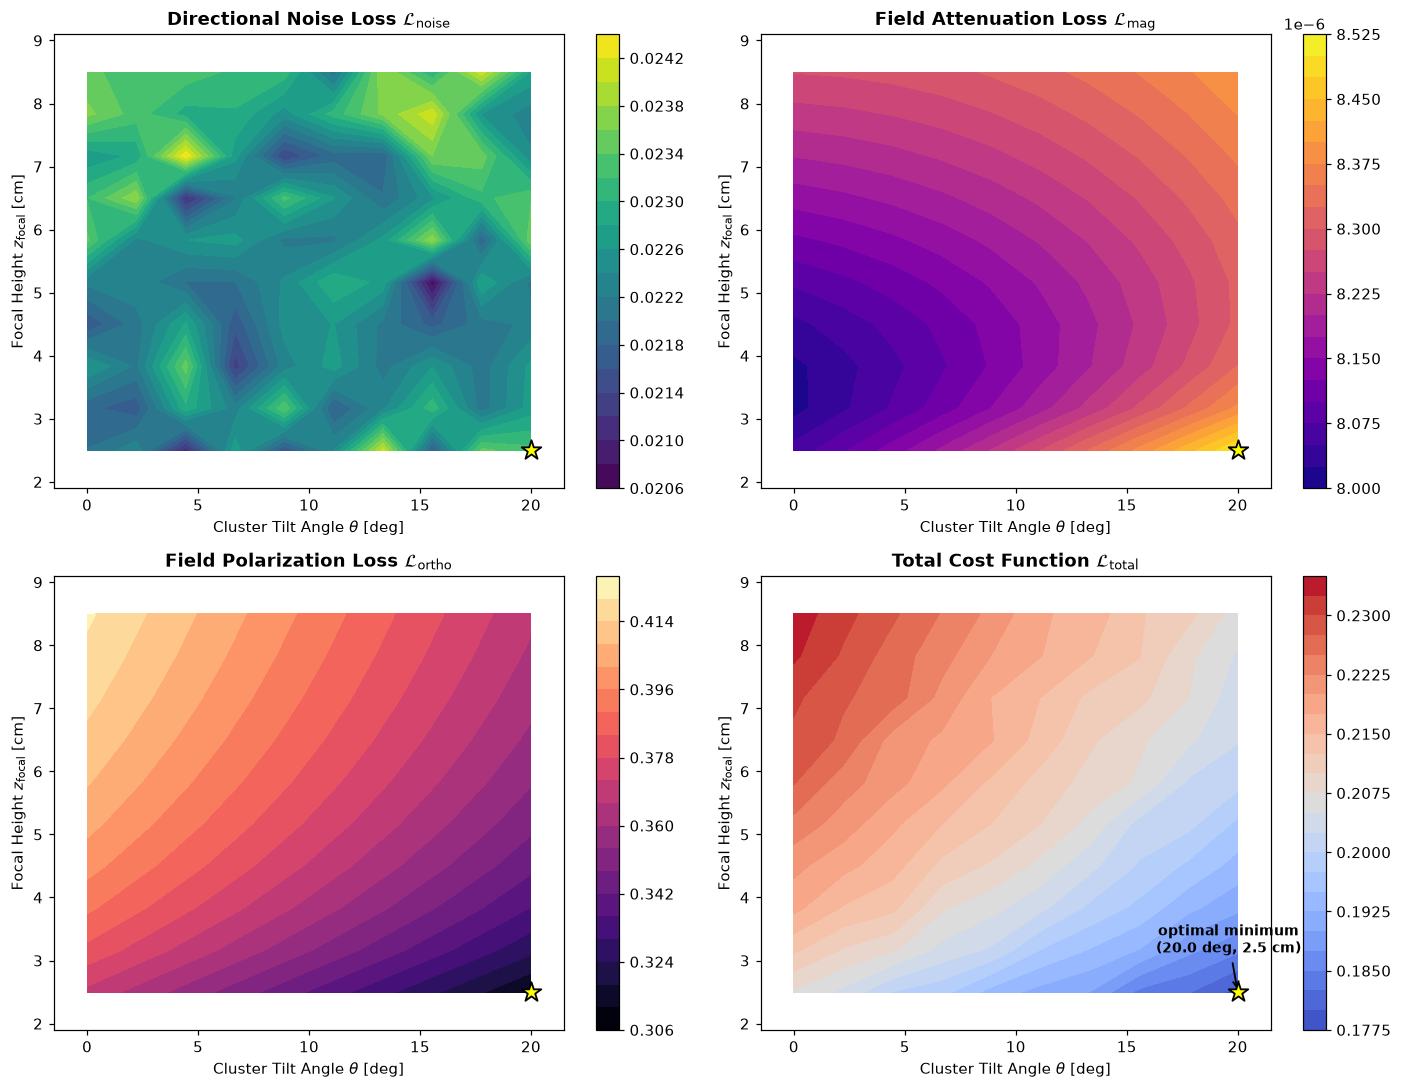

In [7]:
TH, ZF = np.meshgrid(OPTIMAL["theta_vals"], OPTIMAL["z_focal_vals"] * 100)
opt_theta, opt_z_focal = OPTIMAL["theta_deg"], OPTIMAL["z_focal"]

fig, axs = plt.subplots(2, 2, figsize=(13, 10))

c1 = axs[0, 0].contourf(TH, ZF, OPTIMAL["grids"]["noise"], 20, cmap="viridis")
fig.colorbar(c1, ax=axs[0, 0])
axs[0, 0].set_title(r"Directional Noise Loss $\mathcal{L}_{\mathrm{noise}}$", fontweight="bold")
axs[0, 0].set_xlabel(r"Cluster Tilt Angle $\theta$ [deg]")
axs[0, 0].set_ylabel(r"Focal Height $z_{\mathrm{focal}}$ [cm]")

c2 = axs[0, 1].contourf(TH, ZF, OPTIMAL["grids"]["mag"], 20, cmap="plasma")
fig.colorbar(c2, ax=axs[0, 1])
axs[0, 1].set_title(r"Field Attenuation Loss $\mathcal{L}_{\mathrm{mag}}$", fontweight="bold")
axs[0, 1].set_xlabel(r"Cluster Tilt Angle $\theta$ [deg]")
axs[0, 1].set_ylabel(r"Focal Height $z_{\mathrm{focal}}$ [cm]")

c3 = axs[1, 0].contourf(TH, ZF, OPTIMAL["grids"]["ortho"], 20, cmap="magma")
fig.colorbar(c3, ax=axs[1, 0])
axs[1, 0].set_title(r"Field Polarization Loss $\mathcal{L}_{\mathrm{ortho}}$", fontweight="bold")
axs[1, 0].set_xlabel(r"Cluster Tilt Angle $\theta$ [deg]")
axs[1, 0].set_ylabel(r"Focal Height $z_{\mathrm{focal}}$ [cm]")

c4 = axs[1, 1].contourf(TH, ZF, OPTIMAL["grids"]["total"], 25, cmap="coolwarm")
fig.colorbar(c4, ax=axs[1, 1])
axs[1, 1].set_title(r"Total Cost Function $\mathcal{L}_{\mathrm{total}}$", fontweight="bold")

# Mark the optimal minimum on every panel, with a margin so a boundary
# optimum (which this sweep finds) is never clipped off the axes.
for ax in axs.ravel():
    ax.scatter(
        [opt_theta], [opt_z_focal * 100], s=180, marker="*",
        facecolor="yellow", edgecolor="black", linewidth=1.2, zorder=6,
    )
    ax.set_xlim(OPTIMAL["theta_vals"][0] - 1.5, OPTIMAL["theta_vals"][-1] + 1.5)
    ax.set_ylim(OPTIMAL["z_focal_vals"][0] * 100 - 0.6,
                OPTIMAL["z_focal_vals"][-1] * 100 + 0.6)
    ax.set_xlabel(r"Cluster Tilt Angle $\theta$ [deg]")
    ax.set_ylabel(r"Focal Height $z_{\mathrm{focal}}$ [cm]")

axs[1, 1].annotate(
    f"optimal minimum\n({opt_theta:.1f} deg, {opt_z_focal*100:.1f} cm)",
    xy=(opt_theta, opt_z_focal * 100), xytext=(-6, 26),
    textcoords="offset points", ha="center",
    arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
    fontsize=9, fontweight="bold",
)
plt.tight_layout()
plt.show()

## 6. Benchmarking the optimal design

Compare the returned optimal configuration against the baseline and fixed tilts,
using more Monte-Carlo samples for a lower-variance estimate.

In [8]:
benchmarks = {
    "Baseline (0 deg Tilt)": get_coil_normals("baseline"),
    "Cluster Tilt (5 deg)": get_coil_normals("cluster_tilt", theta_deg=5.0),
    "Cluster Tilt (10 deg)": get_coil_normals("cluster_tilt", theta_deg=10.0),
    OPTIMAL["label"]: OPTIMAL["normals"],
}

results = {}
print("=" * 78)
print(f"{'Topology':<32} | {'L_noise':<9} | {'L_mag':<9} | {'L_ortho':<9} | {'L_total':<9}")
print("=" * 78)

for name, norm_set in benchmarks.items():
    l_tot, l_n, l_m, l_o = compute_total_loss(norm_set, N_mc=150)
    results[name] = (l_n, l_m, l_o, l_tot)
    print(f"{name:<32} | {l_n:<9.4f} | {l_m:<9.4f} | {l_o:<9.4f} | {l_tot:<9.4f}")
print("=" * 78)

Topology                         | L_noise   | L_mag     | L_ortho   | L_total  


Baseline (0 deg Tilt)            | 0.0254    | 0.0000    | 0.4550    | 0.2529   


Cluster Tilt (5 deg)             | 0.0251    | 0.0000    | 0.4271    | 0.2387   


Cluster Tilt (10 deg)            | 0.0251    | 0.0000    | 0.3989    | 0.2246   


Optimal hybrid (20.0 deg, 2.5 cm) | 0.0227    | 0.0000    | 0.3117    | 0.1786   


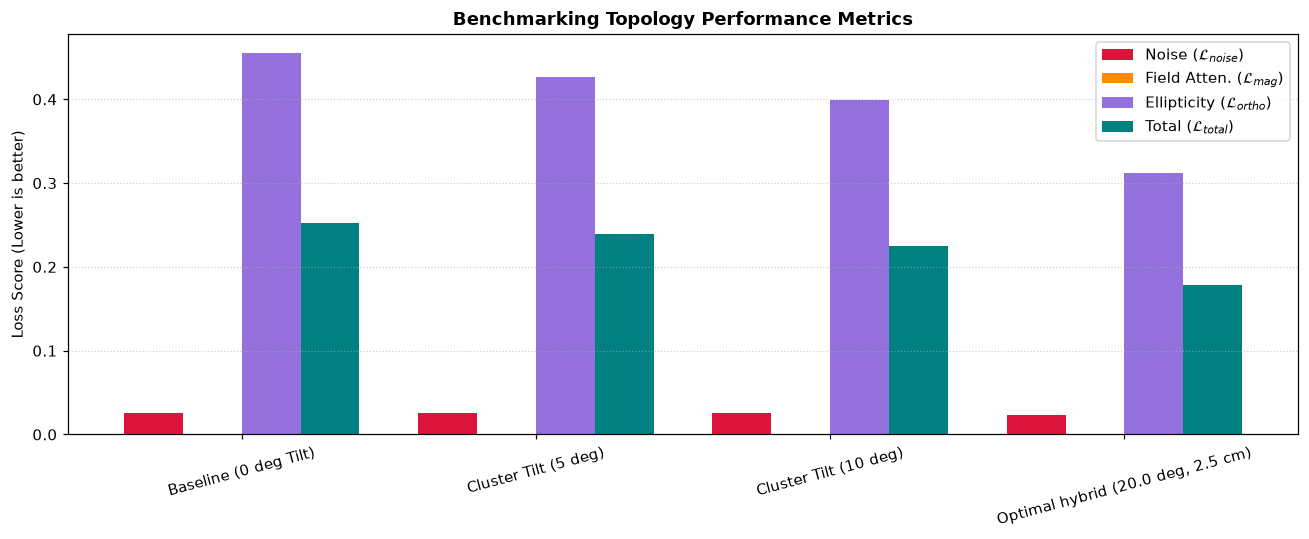

In [9]:
labels = list(results.keys())
l_noise_vals = [results[k][0] for k in labels]
l_mag_vals = [results[k][1] for k in labels]
l_ortho_vals = [results[k][2] for k in labels]
l_tot_vals = [results[k][3] for k in labels]

x = np.arange(len(labels))
width = 0.2

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x - 1.5 * width, l_noise_vals, width, label=r"Noise ($\mathcal{L}_{noise}$)", color="crimson")
ax.bar(x - 0.5 * width, l_mag_vals, width, label=r"Field Atten. ($\mathcal{L}_{mag}$)", color="darkorange")
ax.bar(x + 0.5 * width, l_ortho_vals, width, label=r"Ellipticity ($\mathcal{L}_{ortho}$)", color="mediumpurple")
ax.bar(x + 1.5 * width, l_tot_vals, width, label=r"Total ($\mathcal{L}_{total}$)", color="teal")

ax.set_ylabel("Loss Score (Lower is better)")
ax.set_title("Benchmarking Topology Performance Metrics", fontweight="bold", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=15)
ax.legend()
ax.grid(True, axis="y", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

## 7. The optimal coil configuration, drawn as cylinders

The optimal configuration returned by `optimize_design()` is rendered as the physical
sub-coil hardware: a $4\times4$ array of cylinders, each oriented along its unit normal
$\mathbf{n}_{i,j}$ and coloured by its tilt from the vertical.

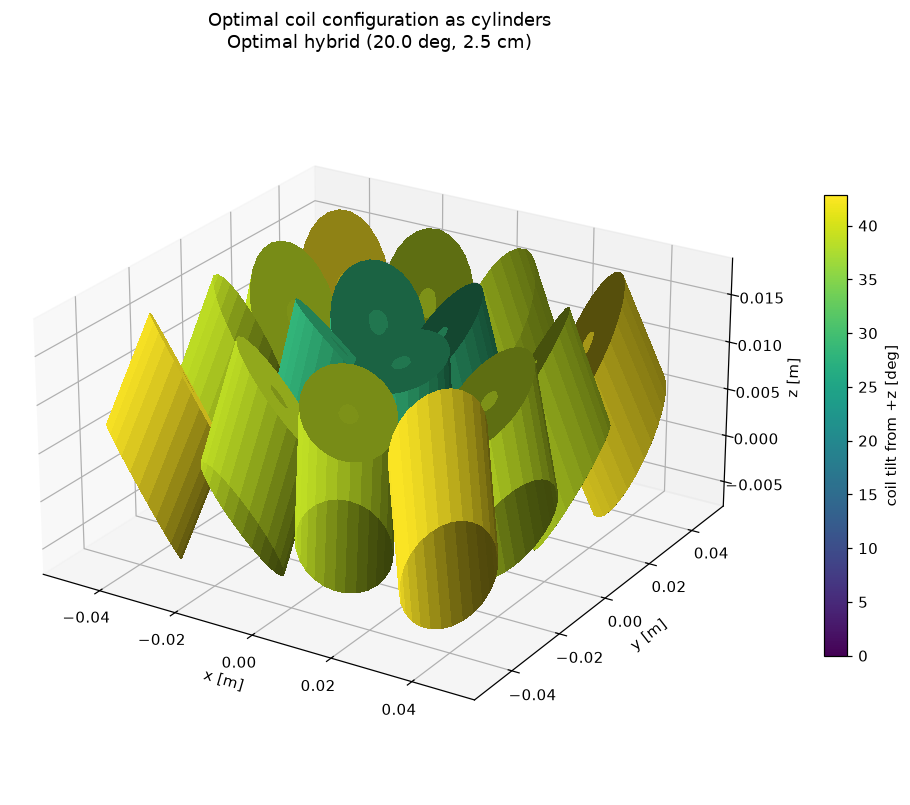

Optimal coil configuration: Optimal hybrid (20.0 deg, 2.5 cm)
 k |   x [mm] |   y [mm] |      nx |      ny |      nz | tilt [deg]
--------------------------------------------------------------------------
 0 |    -39.0 |    -39.0 |   0.481 |   0.481 |   0.734 |      42.81
 1 |    -39.0 |    -13.0 |   0.563 |   0.274 |   0.780 |      38.73
 2 |    -39.0 |     13.0 |   0.563 |  -0.274 |   0.780 |      38.73
 3 |    -39.0 |     39.0 |   0.481 |  -0.481 |   0.734 |      42.81
 4 |    -13.0 |    -39.0 |   0.274 |   0.563 |   0.780 |      38.73
 5 |    -13.0 |    -13.0 |   0.334 |   0.334 |   0.882 |      28.17
 6 |    -13.0 |     13.0 |   0.334 |  -0.334 |   0.882 |      28.17
 7 |    -13.0 |     39.0 |   0.274 |  -0.563 |   0.780 |      38.73
 8 |     13.0 |    -39.0 |  -0.274 |   0.563 |   0.780 |      38.73
 9 |     13.0 |    -13.0 |  -0.334 |   0.334 |   0.882 |      28.17
10 |     13.0 |     13.0 |  -0.334 |  -0.334 |   0.882 |      28.17
11 |     13.0 |     39.0 |  -0.274 |  -0.563 | 

In [10]:
def _align_z_to(n):
    """Rotation matrix that maps +z onto the unit vector n (Rodrigues)."""
    n = np.asarray(n, float)
    n = n / np.linalg.norm(n)
    z = np.array([0.0, 0.0, 1.0])
    v = np.cross(z, n)
    c = float(np.dot(z, n))
    if np.linalg.norm(v) < 1e-12:
        return np.eye(3) if c > 0 else np.diag([1.0, -1.0, -1.0])
    vx = np.array([[0.0, -v[2], v[1]], [v[2], 0.0, -v[0]], [-v[1], v[0], 0.0]])
    return np.eye(3) + vx + vx @ vx / (1.0 + c)


def cylinder_meshes(center, normal, radius, height, n_theta=28):
    """Side wall, top cap and bottom cap of an oriented cylinder."""
    R = _align_z_to(normal)
    center = np.asarray(center, float)[:, None]
    th = np.linspace(0.0, 2.0 * np.pi, n_theta)

    TH, ZZ = np.meshgrid(th, np.array([0.0, height]))
    side = np.stack([radius * np.cos(TH), radius * np.sin(TH), ZZ]).reshape(3, -1)
    side = (R @ side + center).reshape(3, *TH.shape)

    rr = np.linspace(0.0, radius, 6)
    THc, Rc = np.meshgrid(th, rr)
    cap = np.stack([Rc * np.cos(THc), Rc * np.sin(THc), np.full_like(Rc, height)])
    cap = (R @ cap.reshape(3, -1) + center).reshape(3, *THc.shape)
    bot = np.stack([Rc * np.cos(THc), Rc * np.sin(THc), np.zeros_like(Rc)])
    bot = (R @ bot.reshape(3, -1) + center).reshape(3, *THc.shape)
    return side, cap, bot


def draw_coil_array(ax, config, alpha=1.0, caps=True, n_theta=28):
    """Draw every sub-coil of `config` as an oriented cylinder."""
    pos, nrm = config["positions"], config["normals"]
    tilts = np.degrees(np.arccos(np.clip(np.abs(nrm[:, 2]), -1.0, 1.0)))
    norm = plt.Normalize(0.0, max(tilts.max(), 1e-6))
    for k in range(len(pos)):
        color = plt.cm.viridis(norm(tilts[k]))
        side, top, bot = cylinder_meshes(pos[k], nrm[k], COIL_RADIUS, COIL_HEIGHT, n_theta)
        ax.plot_surface(*side, color=color, alpha=alpha, linewidth=0,
                        antialiased=False, shade=True)
        if caps:
            ax.plot_surface(*top, color=color, alpha=alpha, linewidth=0,
                            antialiased=False, shade=True)
            ax.plot_surface(*bot, color=color, alpha=alpha, linewidth=0,
                            antialiased=False, shade=True)
    return plt.cm.ScalarMappable(norm=norm, cmap="viridis")


def plot_coil_configuration(config, elev=24, azim=-58):
    """Dedicated 3-D render of the optimal sub-coil array as cylinders."""
    fig = plt.figure(figsize=(9, 7.5))
    ax = fig.add_subplot(111, projection="3d")

    half = 0.5 * (grid_coords[-1] - grid_coords[0]) * spacing + COIL_RADIUS * 1.6
    base_x = np.array([[-half, half], [-half, half]])
    ax.plot_surface(base_x, base_x.T, np.zeros((2, 2)), color="0.85",
                    alpha=0.5, linewidth=0)

    sm = draw_coil_array(ax, config)
    sm.set_array([])
    fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.08, label="coil tilt from +z [deg]")

    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_zlabel("z [m]")
    ax.set_box_aspect((1, 1, 0.55))
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(f"Optimal coil configuration as cylinders\n{config['label']}")
    plt.tight_layout()
    return fig


fig = plot_coil_configuration(OPTIMAL)
plt.show()

# The returned configuration in tabular form
nrm = OPTIMAL["normals"]
tilts = np.degrees(np.arccos(np.clip(np.abs(nrm[:, 2]), -1.0, 1.0)))
print(f"Optimal coil configuration: {OPTIMAL['label']}")
print(f"{'k':>2} | {'x [mm]':>8} | {'y [mm]':>8} | {'nx':>7} | {'ny':>7} | {'nz':>7} | {'tilt [deg]':>10}")
print("-" * 74)
for k in range(N_COILS):
    x, y, _ = OPTIMAL["positions"][k]
    print(f"{k:>2} | {x*1e3:>8.1f} | {y*1e3:>8.1f} | {nrm[k,0]:>7.3f} | "
          f"{nrm[k,1]:>7.3f} | {nrm[k,2]:>7.3f} | {tilts[k]:>10.2f}")

## 8. Interactive rotation-axis surface

At a chosen layer $z$, the rotating field has a local rotation axis
$\mathbf{n}_{\mathrm{rot}}(\mathbf{r})$ (the normal of the plane in which
$\mathbf{B}$ rotates). We render a surface whose **local normal equals
$\mathbf{n}_{\mathrm{rot}}$ at every point**.

A height field $z_s(x,y) = z + h(x,y)$ has upward normal
$$\mathbf{N} = \frac{(-\partial_x h,\, -\partial_y h,\, 1)}{\sqrt{(\partial_x h)^2 + (\partial_y h)^2 + 1}}.$$
Setting $\mathbf{N} = \mathbf{n}_{\mathrm{rot}} = (n_x,n_y,n_z)$ gives the gradient
$\partial_x h = -n_x/n_z$ and $\partial_y h = -n_y/n_z$, which we integrate with the
**Frankot-Chellappa** least-squares solver (an FFT Poisson solve).

### Why the surface is a convex dome

For this array the rotation axis fans **outward** from the centre: $n_r > 0$ and
$n_z$ decreases with radius. Hence $\partial h/\partial r = -n_r/n_z < 0$, so $h$ is
maximal on the axis and the surface is a **convex dome**. Two things made an earlier
version *look* concave:

* a **square** domain reaches $r = \sqrt{2}\,L$ at its corners, where the axis is much
  more tilted, pulling the sheet into four deep corner dips; and
* the layer's reference plane cut through the dome like a waterline.

Both are gone: the domain is now **circular** (radius $L$) and there is no reference
plane, so the convex dome reads cleanly. Where the axis becomes (near) horizontal,
$n_z \to 0$ and a graph surface cannot represent it; the slider keeps the domain small
enough that the axis stays within a bounded cone.

In [11]:
OPTIMAL_NORMALS = OPTIMAL["normals"]

TOPOLOGIES = {
    "Baseline (flat)": get_coil_normals("baseline"),
    "Cluster tilt (10 deg)": get_coil_normals("cluster_tilt", theta_deg=10.0),
    "Focal convergent (4.5 cm)": get_coil_normals("focal_convergent", z_focal=0.045),
    OPTIMAL["label"]: OPTIMAL_NORMALS,
}


def frankot_chellappa(p, q, dx, dy):
    """Least-squares h(x, y) from its gradients p = dh/dx, q = dh/dy.

    Solves the Poisson equation in the Fourier domain (Frankot-Chellappa 1988),
    reconstructing an integrable surface from a possibly non-integrable normal
    field."""
    ny, nx = p.shape
    fx = fftfreq(nx, d=dx)[None, :]
    fy = fftfreq(ny, d=dy)[:, None]
    denom = (2 * np.pi * fx) ** 2 + (2 * np.pi * fy) ** 2
    denom[0, 0] = 1.0
    H = (-1j * 2 * np.pi * fx * fft2(p) - 1j * 2 * np.pi * fy * fft2(q)) / denom
    H[0, 0] = 0.0
    return np.real(ifft2(H))


def rotation_axis_surface(normals, z_mm, L_mm, n=61, nz_floor=0.05):
    """Height field whose unit normal equals the local rotation axis n_rot.

    Returns X, Y, layer height z (m), ripple h (m), n_rot, B_rms, tilt (deg) and
    a validity mask (True outside the circular domain or where the axis is too
    horizontal to be a surface normal)."""
    z = z_mm * 1e-3
    L = L_mm * 1e-3
    xs = np.linspace(-L, L, n)
    ys = np.linspace(-L, L, n)
    X, Y = np.meshgrid(xs, ys)

    _, _, n_rot, b_rms, tilt_deg = field_observables(normals, z, X, Y)
    nz = np.clip(n_rot[..., 2], nz_floor, 1.0)

    # Integrate on the full square grid, then mask for display.
    h = frankot_chellappa(
        -n_rot[..., 0] / nz, -n_rot[..., 1] / nz, xs[1] - xs[0], ys[1] - ys[0]
    )
    outside = np.hypot(X, Y) > L            # circular layer
    mask = outside | (n_rot[..., 2] < nz_floor)
    h[mask] = np.nan
    return X, Y, z, h, n_rot, b_rms, tilt_deg, mask


def plot_rotation_axis_surface(
    z_mm=20.0, L_mm=10.0, topology=None, n=61,
    elev=32, azim=-58, show_coils=True,
):
    """Render the normal-matching (convex) surface at layer z_mm."""
    if topology is None:
        topology = OPTIMAL["label"]
    normals = TOPOLOGIES[topology]
    X, Y, z, h, n_rot, b_rms, tilt_deg, mask = rotation_axis_surface(
        normals, z_mm, L_mm, n
    )
    Z = z + h

    hmin, hmax = np.nanmin(h), np.nanmax(h)
    mid = n // 2
    h_center = h[mid, mid]
    h_edge = np.nanmean(h[np.hypot(X, Y) > 0.9 * L_mm * 1e-3])
    shape = "convex dome" if h_center > h_edge else "concave bowl"

    fig = plt.figure(figsize=(9, 7.5))
    ax = fig.add_subplot(111, projection="3d")

    norm = plt.Normalize(np.nanmin(b_rms), np.nanmax(b_rms))
    ax.plot_surface(
        X, Y, Z, facecolors=plt.cm.viridis(norm(b_rms)),
        rstride=1, cstride=1, linewidth=0, antialiased=True, shade=False,
    )

    if show_coils:
        draw_coil_array(ax, OPTIMAL, alpha=0.30, caps=False, n_theta=16)

    sm = plt.cm.ScalarMappable(norm=norm, cmap="viridis")
    sm.set_array([])
    fig.colorbar(sm, ax=ax, shrink=0.55, pad=0.08, label=r"$B_{\mathrm{rms}}$ [T]")

    pad = 0.12 * max(hmax - hmin, 1e-4)
    ax.set_zlim(z + hmin - pad, z + hmax + pad)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_zlabel("z [m]")
    ax.set_box_aspect((1, 1, 0.5))
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(
        f"Rotation-axis surface at z = {z_mm:.0f} mm - {shape}\n"
        f"{topology}, ripple {(hmax - hmin) * 1e3:.1f} mm, "
        f"max axis tilt {np.nanmax(tilt_deg):.1f} deg"
    )
    plt.tight_layout()
    return fig

### Validation: the rendered surface normal equals $\mathbf{n}_{\mathrm{rot}}$

Recompute the analytic normal of the reconstructed height field and compare it to the
true rotation axis. The mismatch is the discretisation error of the FFT solver; the
edge values are larger because the FFT solve is periodic and the gradient is
one-sided there.

In [12]:
X, Y, z, h, n_rot, b_rms, tilt_deg, mask = rotation_axis_surface(
    OPTIMAL_NORMALS, z_mm=20.0, L_mm=10.0, n=121
)
hx = np.gradient(h, axis=1) / (X[0, 1] - X[0, 0])
hy = np.gradient(h, axis=0) / (Y[1, 0] - Y[0, 0])
N = np.stack([-hx, -hy, np.ones_like(h)], axis=2)
N /= np.linalg.norm(N, axis=2, keepdims=True)

err = np.degrees(np.arccos(np.clip(np.sum(N * n_rot, axis=2), -1.0, 1.0)))
r = np.hypot(X, Y)
interior = r < 0.75 * 10e-3        # central region
ring = (r >= 0.75 * 10e-3) & (r < 0.95 * 10e-3)

print("Surface-normal vs true rotation axis n_rot:")
print(f"  interior nodes : max {np.nanmax(err[interior]):.3f} deg, "
      f"mean {np.nanmean(err[interior]):.3f} deg")
print(f"  outer ring     : max {np.nanmax(err[ring]):.3f} deg  "
      f"(larger near the edge: periodic FFT and one-sided gradients)")

hmid = h[h.shape[0] // 2, h.shape[1] // 2]
print(f"\nShape check: h(centre) = {hmid*1e3:+.2f} mm is the maximum of h -> convex dome.")

Surface-normal vs true rotation axis n_rot:
  interior nodes : max 0.048 deg, mean 0.020 deg
  outer ring     : max 0.172 deg  (larger near the edge: periodic FFT and one-sided gradients)

Shape check: h(centre) = +2.96 mm is the maximum of h -> convex dome.


### Static render (default layer)

A fixed render so the notebook always shows the surface, even without live widgets.

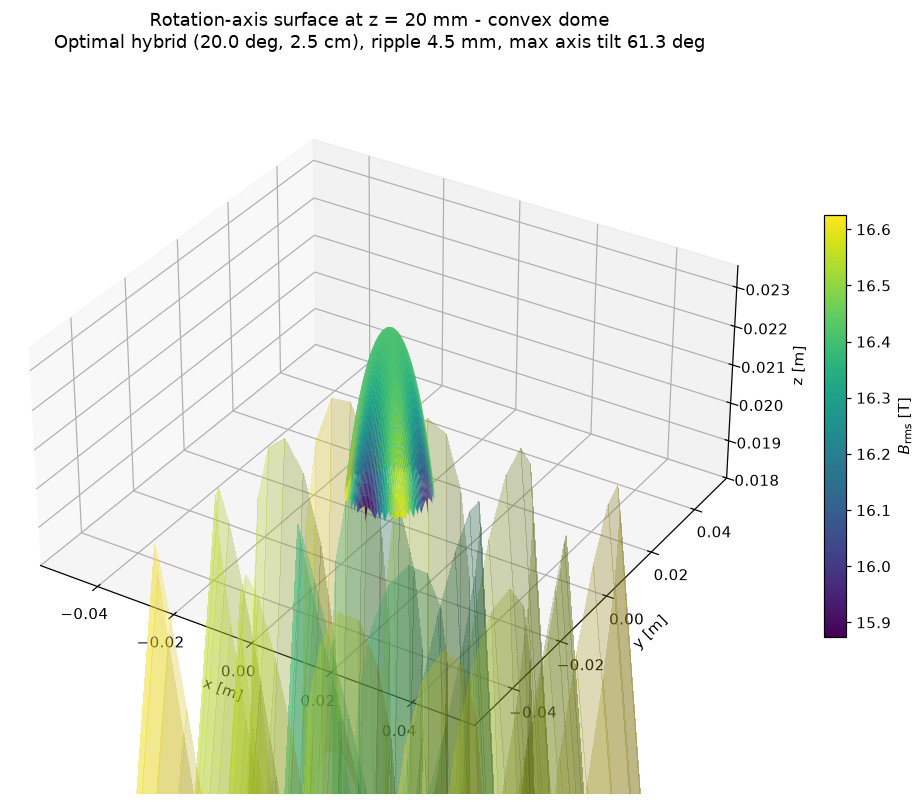

In [13]:
fig = plot_rotation_axis_surface(z_mm=20.0, L_mm=10.0)
plt.show()

### Interactive: slide through the layers

In [14]:
def _render(z_mm, L_mm, topology):
    clear_output(wait=True)
    plot_rotation_axis_surface(z_mm=z_mm, L_mm=L_mm, topology=topology)
    plt.show()


z_slider = widgets.FloatSlider(
    value=20.0, min=5.0, max=50.0, step=1.0,
    description="layer z [mm]", continuous_update=False,
)
L_slider = widgets.FloatSlider(
    value=10.0, min=5.0, max=20.0, step=1.0,
    description="radius [mm]", continuous_update=False,
)
topo_dropdown = widgets.Dropdown(
    options=list(TOPOLOGIES), value=OPTIMAL["label"], description="topology",
)

out = widgets.interactive_output(
    _render, {"z_mm": z_slider, "L_mm": L_slider, "topology": topo_dropdown}
)
display(widgets.HBox([topo_dropdown, z_slider, L_slider]), out)

Output()